In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [8]:
#read the data
df= pd.read_csv('height-weight.csv')
df.head()

,Weight,Height
0,45,120
1,58,135
2,48,123
3,60,145
4,70,160


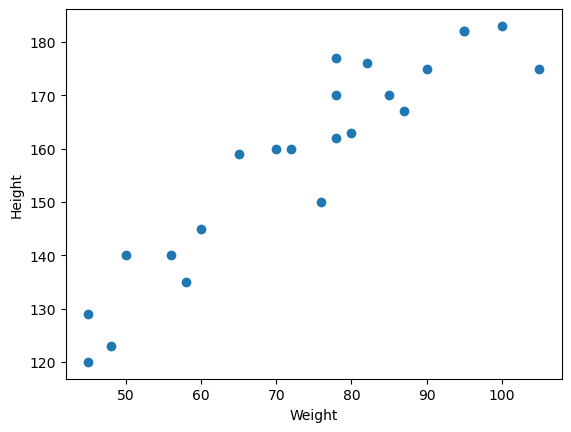

In [12]:
plt.scatter(df.Weight, df.Height)
plt.xlabel('Weight')
plt.ylabel('Height')
plt.show()

In [ ]:
#divide the data into X and y
x = df[['Weight']] #independent feature
y = df[['Height']] #dependent featue


In [23]:
#split the data into train and test
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.25, random_state=1)

In [24]:
x_train,  x_test

(    Weight
 10      82
 4       70
 2       48
 18      76
 6       80
 7       90
 1       58
 14      85
 0       45
 15      78
 22      72
 21      56
 9       78
 8       95
 12     105
 11      95
 5       78,
     Weight
 20      45
 17      65
 3       60
 13     100
 19      87
 16      50)

In [25]:
y_train , y_test

(    Height
 10     176
 4      160
 2      123
 18     150
 6      163
 7      175
 1      135
 14     170
 0      120
 15     177
 22     160
 21     140
 9      170
 8      182
 12     175
 11     182
 5      162,
     Height
 20     129
 17     159
 3      145
 13     183
 19     167
 16     140)

In [26]:
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((17, 1), (6, 1), (17, 1), (6, 1))

In [27]:
#scaling >> use standardization >> fit_traonsform on train data, transform - test data
#scaling should be done after train-test split
#because test data represent unseen data, so we only fit_transform to train and transform to test
from sklearn.preprocessing import StandardScaler



In [28]:
scaler = StandardScaler()
scaler

StandardScaler()

In [29]:
x_train

,Weight
10,82
4,70
2,48
18,76
6,80
7,90
1,58
14,85
0,45
15,78


In [ ]:
#alwaysperform scalling after train test split
#y/target variable should not be scaled
#avoid scaling categorical features.
x_train = scaler.fit_transform(x_train) #for train data use fit_transform
x_test =  scaler.transform(x_test) #for test use only transform because it's unseen data

In [31]:
x_train

array([[ 0.37554243],
       [-0.36825034],
       [-1.73187043],
       [ 0.00364604],
       [ 0.25157697],
       [ 0.87140428],
       [-1.11204312],
       [ 0.56149062],
       [-1.91781863],
       [ 0.12761151],
       [-0.24428488],
       [-1.23600858],
       [ 0.12761151],
       [ 1.18131794],
       [ 1.80114525],
       [ 1.18131794],
       [ 0.12761151]])

In [32]:
x_test

array([[-1.91781863],
       [-0.678164  ],
       [-0.98807766],
       [ 1.49123159],
       [ 0.68545609],
       [-1.60790497]])

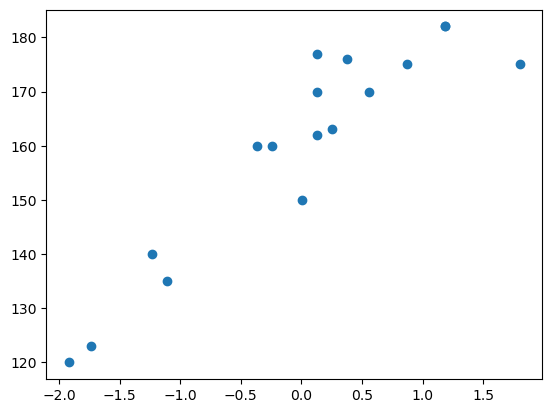

In [ ]:
#data leakage : if we won't divide train and test split, and do fit_transform for all data
#then we already transfering all data to the model so no unseen data is available to machine to test
#scalling is optional >> why?  it's doesn't affect distribution of data
plt.scatter(x_train,y_train)

In [38]:
#model training
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor

LinearRegression()

In [39]:
#parameters in LinearRegression
''' 
fit_intercept >> the best fit line will have intercept by default it's true
copy_x >> copy the original x_train and then build the model, dont modify the original data, by default true
n_jobs >> processor you want to use, if not given use any one processor if -1 given use all the processors
positive >> you want all of your coeficient to be positive

after building the model, you have attributes of the mode
coef
intercept
'''

" \nfit_intercept >> the best fit line will have intercept by default it's true\ncopy_x >> copy the original x_train and then build the model, dont modify the original data, by default true\nn_jobs >> processor you want to use, if not given use any one processor if -1 given use all the processors\npositive >> you want all of your coeficient to be positive\n\nafter building the model, you have attributes of the mode\ncoef\nintercept\n"

In [43]:
#training of the model
regressor.fit(x_train, y_train)

LinearRegression()

In [44]:
print('the slope or coef of model is',regressor.coef_)
print('the intercept of the model is',regressor.intercept_)

the slope or coef of model is [[17.7307072]]
the intercept of the model is [160.]


In [47]:
#prediction of train data
regressor.predict(x_train)

array([[166.65863288],
       [153.47066096],
       [129.29271243],
       [160.06464692],
       [164.46063756],
       [175.45061417],
       [140.28268904],
       [169.95562586],
       [125.99571945],
       [162.26264224],
       [155.66865628],
       [138.08469371],
       [162.26264224],
       [180.94560247],
       [191.93557907],
       [180.94560247],
       [162.26264224]])

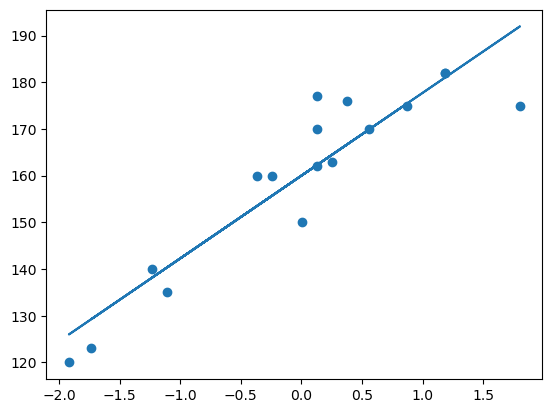

In [46]:
plt.scatter(x_train,y_train)
plt.plot(x_train,regressor.predict(x_train))

In [48]:
y_pred = regressor.predict(x_test)

In [49]:
y_pred, y_test

(array([[125.99571945],
        [147.97567266],
        [142.48068436],
        [186.44059077],
        [172.15362118],
        [131.49070775]]),
     Height
 20     129
 17     159
 3      145
 13     183
 19     167
 16     140)

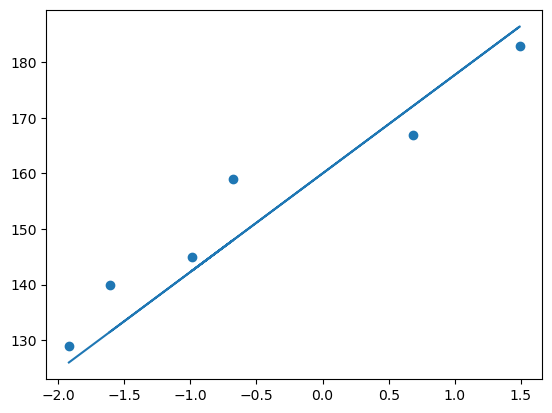

In [50]:
plt.scatter(x_test,y_test)
plt.plot(x_test, y_pred)

In [53]:
#performance metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [54]:
mse=mean_squared_error(y_test,y_pred)
mse

41.28566283045542

In [56]:
mae = mean_absolute_error(y_test,y_pred)
mae

5.608571289304831

In [57]:
rmse =np.sqrt(mse)
rmse

6.425392037102127

In [59]:
#R^2 = 1 - SSR/SST
from sklearn.metrics import r2_score
score =r2_score(y_test,y_pred)
score

0.8721036174256609

In [60]:
#adjusted r square
#r^2 = 1-[(1-r^2)*(n-1)/(n-k-1)] #n is no. of obs, kis no predictor variables
1-(1-score)*(len(y_test)-1)/(len(y_test)-x_test.shape[1]-1)


0.8401295217820761

In [61]:
#to get no. of columns
x_test.shape[1]

1

In [63]:
#new data
ht_scalered = scaler.transform([[60]])
ht_scalered

array([[60.]])

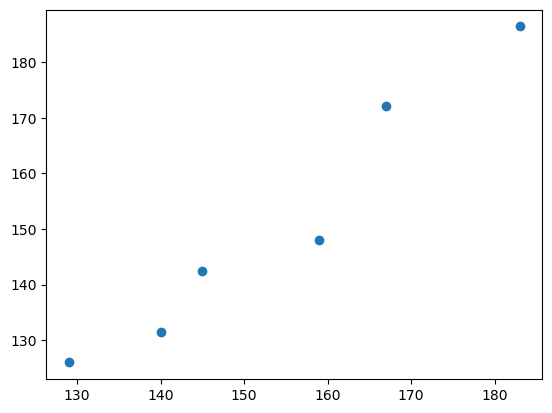

In [64]:
#assuption 
#x-y should have linear relationship
#observation should not have relation
#error should should have constant variance
#error should be normally distribute
plt.scatter(y_test,y_pred)

In [65]:
#residual/error
error= y_test-y_pred
error

,Height
20,3.004281
17,11.024327
3,2.519316
13,-3.440591
19,-5.153621
16,8.509292


C:\Users\nachi\AppData\Local\Temp\ipykernel_16684\1392136830.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(error, kde=True)


<Axes: ylabel='Density'>

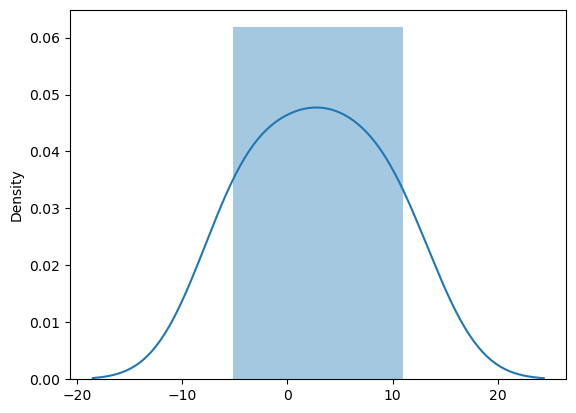

In [67]:
import seaborn as sns
sns.distplot(error, kde=True)

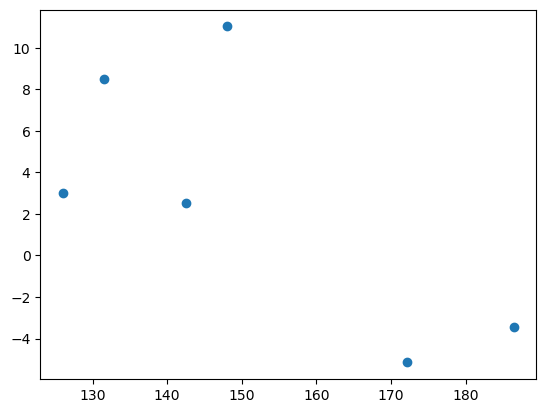

In [69]:
#error should have constant variance
plt.scatter(y_pred,error) #thereis no pattern in those